<a href="https://colab.research.google.com/github/bgeethagayathri2-del/Student-helpdesk-chatbot/blob/main/Helpdesk_chatbot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total training examples: 64
intent
greeting         8
goodbye          8
thanks           8
exam_schedule    8
fees             8
library          8
hostel           8
placements       8
Name: count, dtype: int64
Test accuracy: 0.938
Cross-validation accuracy: 0.799
               precision    recall  f1-score   support

exam_schedule       1.00      1.00      1.00         2
         fees       1.00      1.00      1.00         2
      goodbye       1.00      1.00      1.00         2
     greeting       1.00      1.00      1.00         2
       hostel       1.00      1.00      1.00         2
      library       1.00      1.00      1.00         2
   placements       0.67      1.00      0.80         2
       thanks       1.00      0.50      0.67         2

     accuracy                           0.94        16
    macro avg       0.96      0.94      0.93        16
 weighted avg       0.96      0.94      0.93        16



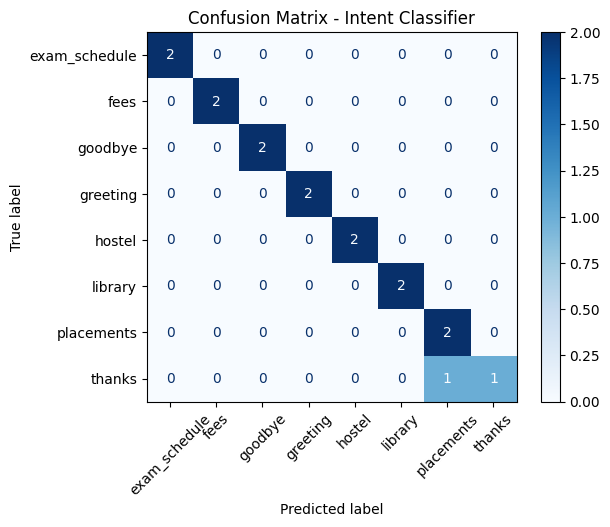

You: hello
Bot: Hello! I am the student helpdesk bot. Ask me about exams, fees, the library, hostel or placements.
     [intent: greeting, confidence: 0.80]

You: what time does the library close
Bot: The library is open on weekdays from morning to evening. You can issue books using your student ID card.
     [intent: library, confidence: 0.72]

You: how do i get a room in the hostel
Bot: Hostel applications are made at the hostel office. Room allotment depends on availability and the hostel rules.
     [intent: hostel, confidence: 0.54]

You: when will the semester exams happen
Bot: Exam timetables are put on the college notice board and website about 2 weeks before the exams.
     [intent: exam_schedule, confidence: 0.68]

You: what is the placement process
Bot: Sorry, I did not understand. Try asking about exams, fees, the library, hostel or placements.
     [intent: unknown, confidence: 0.28]

You: thank you
Bot: You're welcome! Ask me anything else you need.
     [intent: thanks, 

In [1]:
# Student Helpdesk Chatbot (intent classification with NLP)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Training data: example questions (patterns) and answers (responses) for each intent
intents = {
    "greeting": {
        "patterns": ["hi", "hello", "hey there", "good morning", "good evening", "hi bot", "hello there", "hey"],
        "response": "Hello! I am the student helpdesk bot. Ask me about exams, fees, the library, hostel or placements."},
    "goodbye": {
        "patterns": ["bye", "goodbye", "see you later", "see you", "talk to you later", "i am leaving", "catch you later", "bye bye"],
        "response": "Goodbye! Have a great day."},
    "thanks": {
        "patterns": ["thanks", "thank you", "thanks a lot", "thank you so much", "that was helpful", "many thanks", "appreciate it", "great thanks"],
        "response": "You're welcome! Ask me anything else you need."},
    "exam_schedule": {
        "patterns": ["when are the exams", "exam timetable", "when do exams start", "exam dates", "what is the exam schedule", "when is the semester exam", "tell me exam timings", "exam date sheet"],
        "response": "Exam timetables are put on the college notice board and website about 2 weeks before the exams."},
    "fees": {
        "patterns": ["how much is the fee", "fee structure", "what is the tuition fee", "how do i pay fees", "last date to pay fees", "fee payment details", "college fees", "where can i pay the fees"],
        "response": "Fees can be paid at the accounts office or online through the college portal. Check the notice board for the last date."},
    "library": {
        "patterns": ["library timings", "when does the library open", "library opening hours", "is the library open on sunday", "how to borrow books", "library rules", "can i issue a book", "library closing time"],
        "response": "The library is open on weekdays from morning to evening. You can issue books using your student ID card."},
    "hostel": {
        "patterns": ["hostel facilities", "how to apply for hostel", "hostel fees", "is hostel available", "hostel rules", "hostel admission", "room allotment", "hostel mess timings"],
        "response": "Hostel applications are made at the hostel office. Room allotment depends on availability and the hostel rules."},
    "placements": {
        "patterns": ["placement details", "which companies visit", "placement training", "when do placements start", "how to prepare for placements", "campus recruitment", "internship opportunities", "placement cell contact"],
        "response": "The placement cell arranges training, company visits and internships. Contact the placement cell for the schedule."},
}

rows = [(p, intent) for intent, d in intents.items() for p in d["patterns"]]
df = pd.DataFrame(rows, columns=["text", "intent"])
print("Total training examples:", len(df))
print(df["intent"].value_counts())

# 2. Split into training and test examples
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["intent"], test_size=0.25, random_state=42, stratify=df["intent"]
)

# 3. Build and train the model (TF-IDF turns words into numbers, then Logistic Regression)
model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000, C=10)
)
model.fit(X_train, y_train)

# 4. Evaluate
pred = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, pred), 3))
cv = cross_val_score(model, df["text"], df["intent"], cv=5).mean()
print("Cross-validation accuracy:", round(cv, 3))
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=model.classes_),
                       display_labels=model.classes_).plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Intent Classifier")
plt.show()

# 5. Retrain on ALL examples for the final chatbot
model.fit(df["text"], df["intent"])

# 6. The chatbot function: reply only if the model is confident enough
def chatbot(message, threshold=0.3):
    probs = model.predict_proba([message])[0]
    best = probs.argmax()
    intent, confidence = model.classes_[best], probs[best]
    if confidence < threshold:
        return "Sorry, I did not understand. Try asking about exams, fees, the library, hostel or placements.", "unknown", confidence
    return intents[intent]["response"], intent, confidence

# 7. Demo conversation (the last two are off-topic on purpose)
tests = [
    "hello", "what time does the library close", "how do i get a room in the hostel",
    "when will the semester exams happen", "what is the placement process",
    "thank you", "what is the weather today", "who won the cricket match",
]
for msg in tests:
    reply, intent, conf = chatbot(msg)
    print(f"You: {msg}")
    print(f"Bot: {reply}")
    print(f"     [intent: {intent}, confidence: {conf:.2f}]\n")